In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
file = Path('/Users/peidli/work/data/scperturb/RNA_new/WesselsSatija2023.h5ad')
adata = sc.read_h5ad(file)

In [3]:
adata

AnnData object with n_obs × n_vars = 30707 × 21052
    obs: 'ncounts', 'ngenes', 'percent_mito', 'Cell_cycle_phase', 'ncounts_HTO', 'HTO', 'ncounts_ADT', '10X_lane', 'guides', 'nCount_GUIDE', 'CRISPRcas13_Array', 'perturbation', 'Guide.Class', 'UMI.g1', 'UMI.g2', 'ID.g1', 'ID.g2', 'fraction.g1.over.all', 'fraction.g1.over.g2', 'g1.by.g2', 'nperts', 'perturbation_type', 'disease', 'cancer', 'tissue_type', 'cell_line', 'celltype', 'organism', 'percent_ribo'
    var: 'ncounts', 'ncells'
    obsm: 'Sample_Tags', 'Surface_protein'

In [5]:
adata.obs

,ncounts,ngenes,percent_mito,Cell_cycle_phase,ncounts_HTO,HTO,ncounts_ADT,10X_lane,guides,nCount_GUIDE,...,g1.by.g2,nperts,perturbation_type,disease,cancer,tissue_type,cell_line,celltype,organism,percent_ribo
cell_barcode,,,,,,,,,,,,,,,,,,,,,
L1_TGTGAGTAGTTAACAG,15908,3744,8.536585,G1,1792,HTO-52,13376,L1,UID-046,45,...,14.5,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,26.941154
L1_TCAATTCCACTTACAG,23236,4756,6.046652,G1,2290,HTO-22,6731,L1,UID-216,55,...,12.0,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,26.565652
L1_CGTTCTGAGGTTACCT,19865,4883,13.063176,S,4218,HTO-44,12765,L1,UID-380,85,...,38.0,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,19.637129
L1_CTCATTAAGGTCCCGT,19946,4492,7.159330,G1,2640,HTO-21,9473,L1,UID-020,114,...,48.5,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,27.546850
L1_CCAAGCGAGCAAACAT,21521,4830,3.814878,G1,767,HTO-52,8282,L1,UID-232,57,...,46.0,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,24.354756
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
L4_TTGGATGGTTGTTGCA,5028,1850,9.924423,G1,1465,HTO-29,3647,L4,UID-100,28,...,7.0,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,24.426424
L4_TCGGGACCAACAGAGC,1952,1062,9.631148,G1,483,HTO-22,1277,L4,UID-187,9,...,7.0,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,14.839368
L4_ACTATGGGTTGGTGTT,10274,3078,10.375706,S,571,HTO-29,4928,L4,UID-131,17,...,inf,2,CRISPR-cas13,leukemia,True,cell_line,THP-1,monocytes,human,17.654489


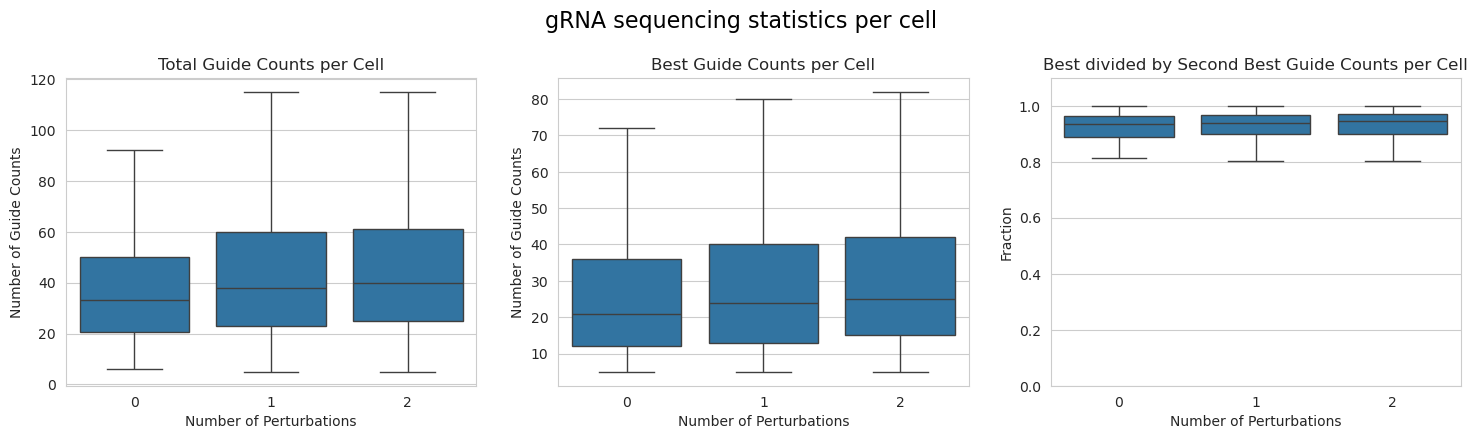

In [6]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(6*3, 4), sharex=True, sharey=False)
ax = axs[0]
sns.boxplot(x='nperts', y='nCount_GUIDE', data=adata.obs, showfliers=False, ax=ax)
ax.set_title('Total Guide Counts per Cell')
ax.set_ylabel('Number of Guide Counts')

ax = axs[1]
sns.boxplot(x='nperts', y='UMI.g1', data=adata.obs, showfliers=False, ax=ax)
ax.set_title('Best Guide Counts per Cell')
ax.set_ylabel('Number of Guide Counts')

ax = axs[2]
sns.boxplot(x='nperts', y='fraction.g1.over.g2', data=adata.obs, showfliers=False, ax=ax)
ax.set_title('Best divided by Second Best Guide Counts per Cell')
ax.set_ylabel('Fraction')
ax.set_ylim(0, 1.1)

for ax in axs:
    ax.set_xlabel('Number of Perturbations')

pl.suptitle('gRNA sequencing statistics per cell', fontsize=16, y=1.05)
pl.show()

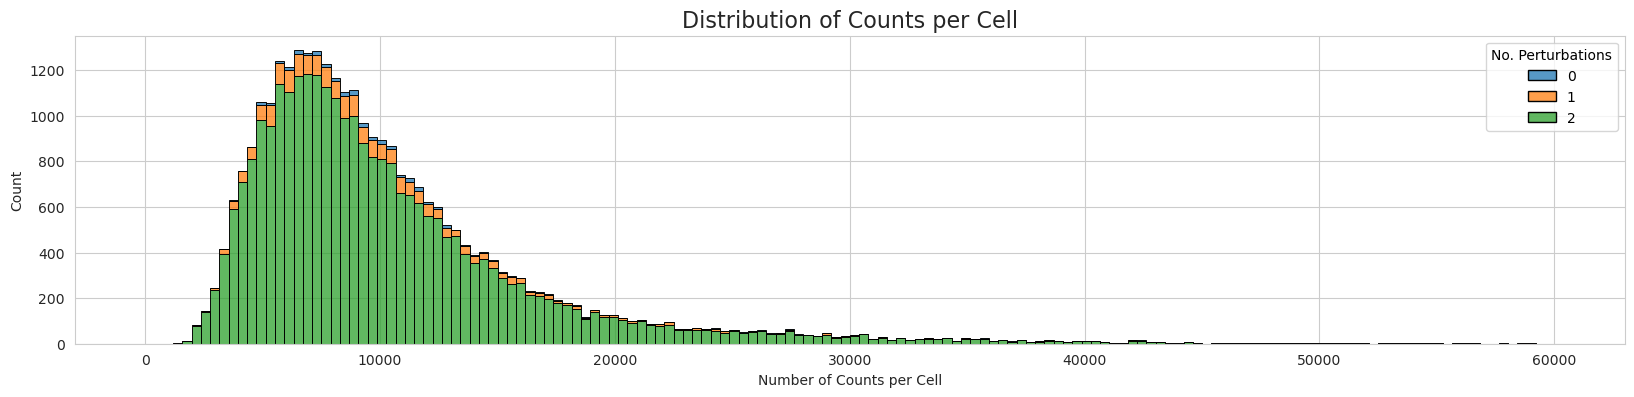

In [7]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(1, 1, figsize=(20, 4))
hist = sns.histplot(data=adata.obs, x='ncounts', ax=ax, binrange=(0, 60000), hue='nperts', multiple='stack', palette='tab10')
ax.set_xlabel('Number of Counts per Cell')
ax.get_legend().set_title('No. Perturbations')
ax.set_title('Distribution of Counts per Cell', fontsize=16)
pl.show()

# Collateral Activity

In [6]:
from statannotations.Annotator import Annotator

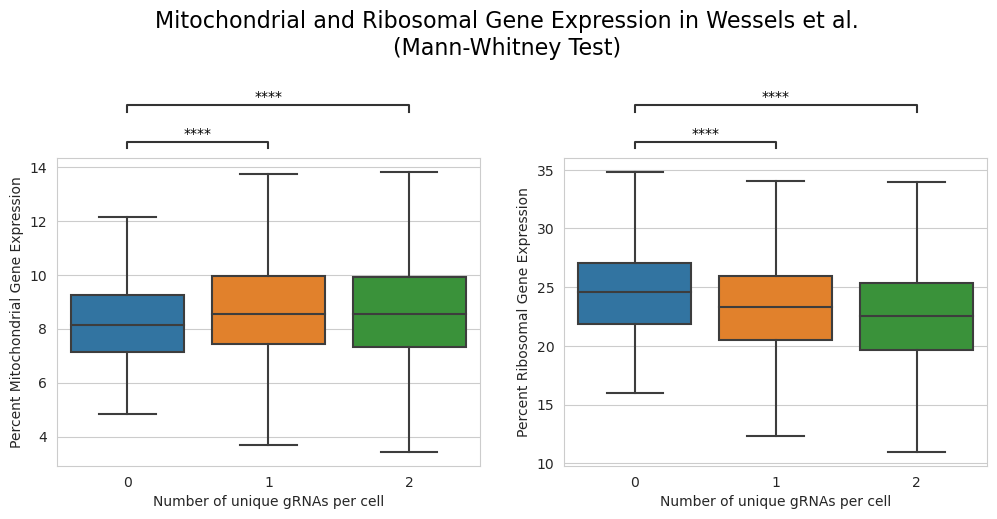

In [17]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(6*2,4))

ax = axs[0]
sns.boxplot(x='nperts', y='percent_mito', data=adata.obs, showfliers=False, ax=ax)
ax.set_ylabel('Percent Mitochondrial Gene Expression')
ax.set_xlabel('Number of unique gRNAs per cell')

annotator = Annotator(ax, [(0, 1), (0,2)], data=adata.obs, x='nperts', y='percent_mito', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

ax = axs[1]
sns.boxplot(x='nperts', y='percent_ribo', data=adata.obs, showfliers=False, ax=ax)
ax.set_ylabel('Percent Ribosomal Gene Expression')
ax.set_xlabel('Number of unique gRNAs per cell')

annotator = Annotator(ax, [(0, 1), (0,2)], data=adata.obs, x='nperts', y='percent_ribo', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

pl.suptitle('Mitochondrial and Ribosomal Gene Expression in Wessels et al.\n(Mann-Whitney Test)', fontsize=16, y=1.25)

pl.show()

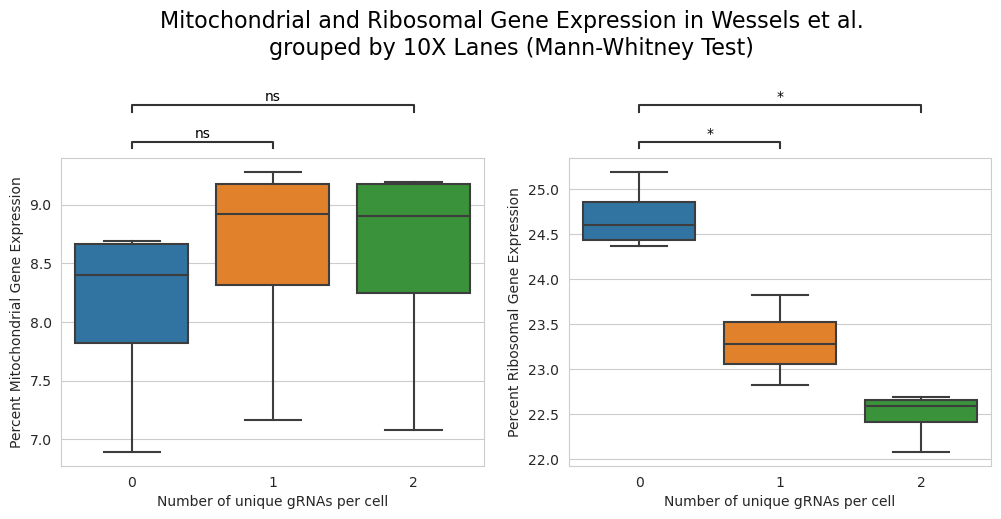

In [36]:
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 2, figsize=(6*2,4))

ax = axs[0]
df = adata.obs.groupby(['nperts', '10X_lane']).mean()['percent_mito'].reset_index()
sns.boxplot(x='nperts', y='percent_mito', data=df, showfliers=False, ax=ax)
ax.set_ylabel('Percent Mitochondrial Gene Expression')
ax.set_xlabel('Number of unique gRNAs per cell')

annotator = Annotator(ax, [(0, 1), (0,2)], data=df, x='nperts', y='percent_mito', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

ax = axs[1]
df = adata.obs.groupby(['nperts', '10X_lane']).mean()['percent_ribo'].reset_index()
sns.boxplot(x='nperts', y='percent_ribo', data=df, showfliers=False, ax=ax)
ax.set_ylabel('Percent Ribosomal Gene Expression')
ax.set_xlabel('Number of unique gRNAs per cell')

annotator = Annotator(ax, [(0, 1), (0,2)], data=df, x='nperts', y='percent_ribo', verbose=0)
annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', show_test_name=True)
annotator.apply_and_annotate()

pl.suptitle('Mitochondrial and Ribosomal Gene Expression in Wessels et al.\ngrouped by 10X Lanes (Mann-Whitney Test)', fontsize=16, y=1.25)

pl.show()